In [ ]:
#Evaluación final en test: detección de la P, predicción de la S y el pipeline completo.
import sys
sys.path.append('..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.linear_model import LinearRegression
from src.data_loader import leer_metadata, cargar, armar_split
from src.dsp_filters import FS, filtrar
from src.detection import sta_lta, primer_cruce, UMBRAL_STA_LTA
from src.forecasting import armar_dataset, features, cargar_cnn, predecir_cnn, ventana
FIGURAS = Path('..') / 'docs' / 'figures'
FIGURAS.mkdir(parents=True, exist_ok=True)

df = leer_metadata()
df['split'] = armar_split(df)['split'].values
df['snr_z'] = df['snr_db'].str.strip('[]').str.split().str[2].astype(float)
sismos = df[df['trace_category'] == 'earthquake_local']
sismos_test = sismos[sismos['split'] == 'test']
ruido_test = df[(df['split'] == 'test') & (df['trace_category'] == 'noise')]

MUERTA = 0.1
TOLERANCIA = int(0.5 * FS)
GRUPOS_SNR = [-np.inf, 10, 20, 30, np.inf]

def canal_z(fila):
    return cargar(fila.trace_name, fila.chunk)[:, 2].astype(float)

len(sismos_test), len(ruido_test)

(86127, 47086)

## Detección de la P sobre Test

STA/LTA con LTA de 5 s y umbral 5.5, elegidos en validación. 2000 sismos y 2000 trazas de ruido de test.

In [ ]:
N_DET = 2000
muestra_s = sismos_test.sample(N_DET, random_state=0)
muestra_r = ruido_test.sample(N_DET, random_state=0)
error = []
for fila in muestra_s.itertuples():
    pk = primer_cruce(sta_lta(filtrar(canal_z(fila))), UMBRAL_STA_LTA)
    error.append(np.nan if pk is None else (pk - fila.p_arrival_sample) / FS)
error = np.array(error)
falsas = []
for fila in muestra_r.itertuples():
    z = canal_z(fila)
    if z.std() >= MUERTA:
        falsas.append(primer_cruce(sta_lta(filtrar(z)), UMBRAL_STA_LTA) is not None)
acierto = np.abs(error) <= 0.5
print(f'Detectados: {acierto.mean() * 100:.1f} %')
print(f'Sin pick: {np.isnan(error).mean() * 100:.1f} %')
print(f'Falsas alarmas: {np.mean(falsas) * 100:.1f} % ({len(falsas)} trazas de ruido)')
grupo = pd.cut(muestra_s['snr_z'], GRUPOS_SNR, labels=['< 10 dB', '10-20 dB', '20-30 dB', '> 30 dB'])
pd.DataFrame({'detectados (%)': acierto * 100, 'SNR': grupo.values}).groupby('SNR', observed=True)['detectados (%)'].agg(['mean', 'count']).round(1)

Detectados: 82.6 %
Sin pick: 7.3 %
Falsas alarmas: 5.2 % (2000 trazas de ruido)


,mean,count
SNR,,
< 10 dB,57.1,163
10-20 dB,68.0,590
20-30 dB,88.0,610
> 30 dB,97.5,637


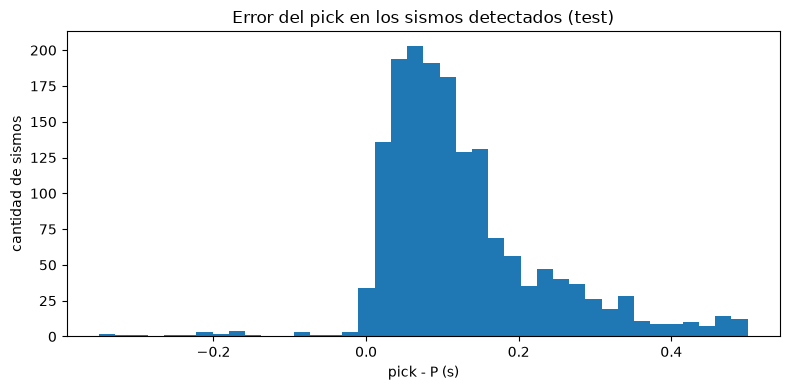

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(error[acierto], bins=40)
ax.set_xlabel('pick - P (s)')
ax.set_ylabel('cantidad de sismos')
ax.set_title('Error del pick en los sismos detectados (test)')
plt.tight_layout()
fig.savefig(FIGURAS / 'error_pick_test.png', dpi=150)

## Amplitud de la S sobre Test

El modelo lineal se vuelve a ajustar con las features de train y la CNN se carga de `models/cnn.pt`. 20000 sismos de test.

In [ ]:
sismos_train = sismos[sismos['split'] == 'train']
X_tr, y_tr, _ = armar_dataset(sismos_train.sample(60000, random_state=0), 'dataset_train')
X_te, y_te, meta_te = armar_dataset(sismos_test.sample(20000, random_state=0), 'dataset_test')
lineal = LinearRegression().fit(np.array([features(w) for w in X_tr]), y_tr)
pred = {
    'promedio': np.full_like(y_te, y_tr.mean()),
    'lineal': lineal.predict(np.array([features(w) for w in X_te])),
    'CNN': predecir_cnn(cargar_cnn(), X_te),
}
errores = pd.DataFrame({nombre: np.abs(p - y_te) for nombre, p in pred.items()})
pd.DataFrame({'MAE (log10)': errores.mean(), 'factor': 10 ** errores.mean()}).round(3)

,MAE (log10),factor
promedio,0.747,5.582
lineal,0.227,1.687
CNN,0.206,1.607


MAE (log10) por magnitud, distancia y SNR.

In [5]:
grupos = {
    'magnitud': pd.cut(meta_te['mag'], [-1, 1, 2, 3, 4, 9]),
    'distancia (km)': pd.cut(meta_te['dist_km'], [0, 25, 50, 100, 400]),
    'SNR (dB)': pd.cut(meta_te['snr'], GRUPOS_SNR),
}
for nombre, g in grupos.items():
    tabla = errores.groupby(g, observed=True).mean()
    tabla['sismos'] = g.value_counts().sort_index()
    print(nombre)
    display(tabla.round(3))

magnitud


,promedio,lineal,CNN,sismos
mag,,,,
"(-1, 1]",0.752,0.210,0.181,4100
"(1, 2]",0.566,0.227,0.207,6370
"(2, 3]",0.706,0.220,0.211,2679
"(3, 4]",1.302,0.256,0.239,1421
"(4, 9]",1.882,0.341,0.295,396


distancia (km)


,promedio,lineal,CNN,sismos
dist_km,,,,
"(0, 25]",0.712,0.241,0.209,1289
"(25, 50]",0.682,0.219,0.197,5299
"(50, 100]",0.755,0.224,0.204,6303
"(100, 400]",0.908,0.249,0.232,2075


SNR (dB)


,promedio,lineal,CNN,sismos
snr,,,,
"(-inf, 10.0]",0.804,0.229,0.207,1362
"(10.0, 20.0]",0.722,0.218,0.193,4459
"(20.0, 30.0]",0.587,0.221,0.200,4456
"(30.0, inf]",0.906,0.241,0.224,4689


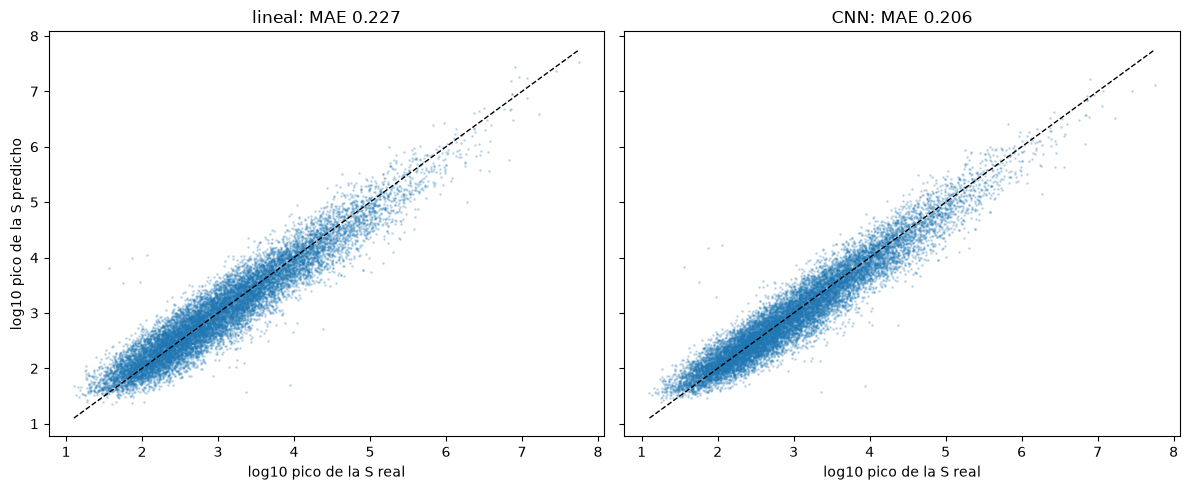

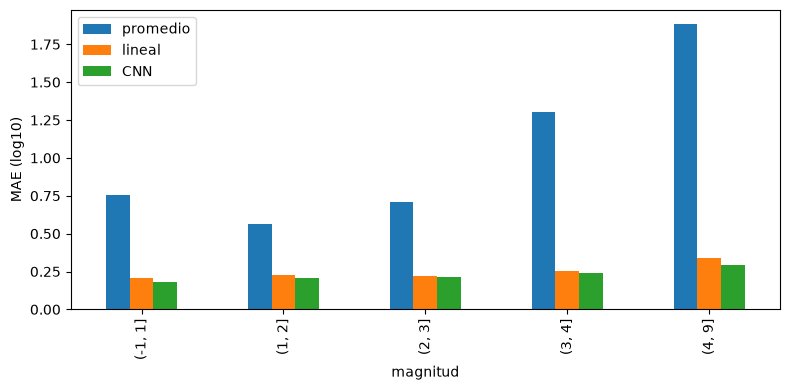

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, nombre in zip(axs, ['lineal', 'CNN']):
    ax.scatter(y_te, pred[nombre], s=1, alpha=0.2)
    ax.plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], 'k--', lw=1)
    ax.set_title(f'{nombre}: MAE {errores[nombre].mean():.3f}')
    ax.set_xlabel('log10 pico de la S real')
axs[0].set_ylabel('log10 pico de la S predicho')
plt.tight_layout()
fig.savefig(FIGURAS / 'prediccion_vs_real.png', dpi=150)
fig, ax = plt.subplots(figsize=(8, 4))
errores.groupby(grupos['magnitud'], observed=True).mean().plot.bar(ax=ax)
ax.set_xlabel('magnitud')
ax.set_ylabel('MAE (log10)')
plt.tight_layout()
fig.savefig(FIGURAS / 'mae_por_magnitud.png', dpi=150)

En testeo, la CNN tiene MAE 0.206 (factor 1.61) y la lineal 0.227 (factor 1.69), casi lo mismo que en validación. La CNN es mejor en todos los grupos.

El error crece con la magnitud: en los sismos de magnitud mayor a 4, que son los que importan para una alerta y los menos frecuentes en el dataset, la CNN tiene MAE 0.295 (factor 2). La distancia y la SNR casi no cambian el error.

## Pipeline completo

Como sería en la realidad: la ventana de 3 s arranca en el pick del STA/LTA en vez de en la P marcada por el dataset de STEAD. Se usan los primeros 2000 sismos de test del dataset y la CNN.

In [ ]:
N_PIPE = 2000
X_pick, idx = [], []
for i in range(N_PIPE):
    fila = meta_te.iloc[i]
    trf = filtrar(cargar(fila['trace_name'], int(fila['chunk'])).astype(float))
    pk = primer_cruce(sta_lta(trf[:, 2]), UMBRAL_STA_LTA)
    if pk is None or pk + 300 > len(trf):
        continue
    X_pick.append(ventana(trf, pk))
    idx.append(i)
X_pick, idx = np.array(X_pick, dtype=np.float32), np.array(idx)
err_pick = np.abs(predecir_cnn(cargar_cnn(), X_pick) - y_te[idx])
print(f'Sin pick: {(1 - len(idx) / N_PIPE) * 100:.1f} %')
print(f'CNN con la P de STEAD: MAE {errores["CNN"].iloc[idx].mean():.3f}')
print(f'CNN con el pick del STA/LTA: MAE {err_pick.mean():.3f}')

Sin pick: 8.4 %
CNN con la P de STEAD: MAE 0.209
CNN con el pick del STA/LTA: MAE 0.215


Con el pick del STA/LTA el error sube poco, de 0.209 a 0.215. Lo que más cuesta del detector es el 8.4 % de sismos sin pick, que se quedan sin predicción.

## Espectrograma

Un sismo de test con SNR alta, canal Z sin filtrar. Las líneas marcan la P y la S.

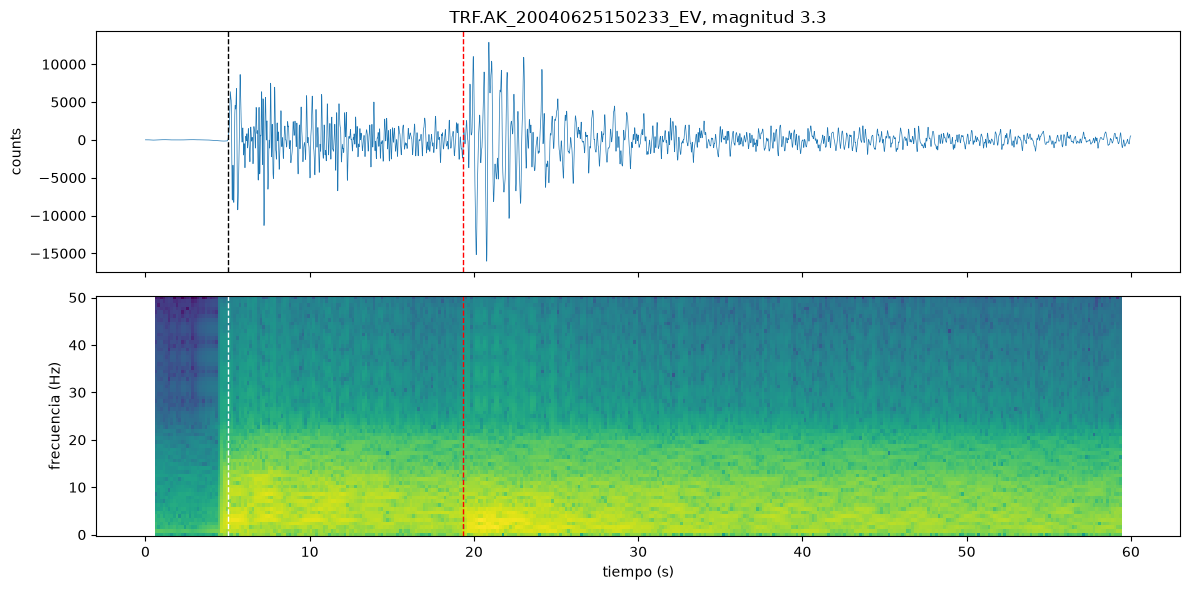

In [ ]:
ej = sismos_test[(sismos_test['snr_z'] > 40) & (sismos_test['source_magnitude'] > 3)].sample(1, random_state=0).iloc[0]
z = cargar(ej['trace_name'], ej['chunk'])[:, 2]
f, t, S = signal.spectrogram(z, fs=FS, nperseg=128, noverlap=112)
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axs[0].plot(np.arange(len(z)) / FS, z, lw=0.5)
axs[0].set_ylabel('counts')
axs[0].set_title(f"{ej['trace_name']}, magnitud {ej['source_magnitude']}")
axs[1].pcolormesh(t, f, 10 * np.log10(S + 1e-20), shading='auto')
axs[1].set_ylabel('frecuencia (Hz)')
axs[1].set_xlabel('tiempo (s)')
for ax in axs:
    ax.axvline(ej['p_arrival_sample'] / FS, color='w' if ax is axs[1] else 'k', ls='--', lw=1)
    ax.axvline(ej['s_arrival_sample'] / FS, color='r', ls='--', lw=1)
plt.tight_layout()
fig.savefig(FIGURAS / 'espectrograma.png', dpi=150)

Antes de la P casi no hay energía. Con la P aparece energía hasta unos 20 Hz, y con la S la energía es mayor y se concentra en frecuencias más bajas.